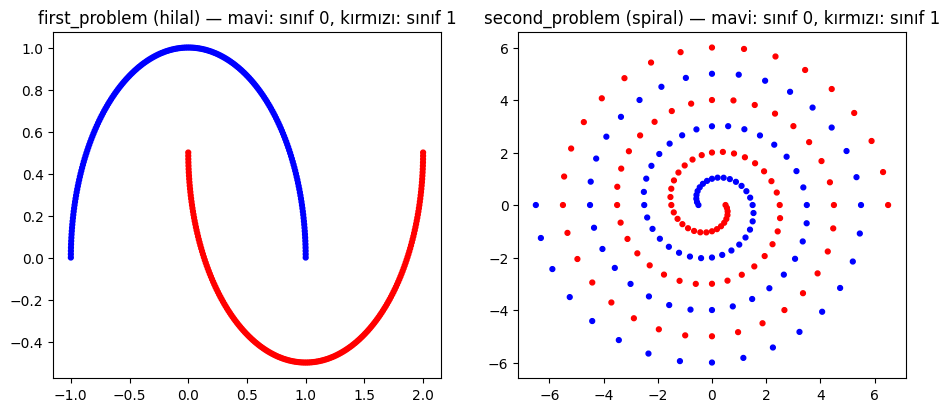

In [1]:
import numpy as np              
import pandas as pd             
import matplotlib.pyplot as plt  


df1 = pd.read_csv("first_problem.csv")   
X1 = df1[["x1", "x2"]].to_numpy()        
y1 = df1["label"].to_numpy()          


df2 = pd.read_csv("second_problem.csv")
X2 = df2[["x1", "x2"]].to_numpy()
y2 = df2["label"].to_numpy()



datasets = {
    "first_problem (hilal)":   (X1, y1),
    "second_problem (spiral)": (X2, y2),
}


plt.figure(figsize=(11, 4.5))

plt.subplot(1, 2, 1)                                      
plt.scatter(X1[:, 0], X1[:, 1], c=y1, cmap="bwr", s=12)   
plt.title("first_problem (hilal) — mavi: sınıf 0, kırmızı: sınıf 1")

plt.subplot(1, 2, 2)                                    
plt.scatter(X2[:, 0], X2[:, 1], c=y2, cmap="bwr", s=12)
plt.title("second_problem (spiral) — mavi: sınıf 0, kırmızı: sınıf 1")

plt.show()

In [2]:

X_or = np.array([[1, 0, 0],
                 [1, 0, 1],
                 [1, 1, 0],
                 [1, 1, 1]])
y_or = np.array([0, 1, 1, 1])


w = np.zeros(3)    
eta = 0.5          

for epoch in range(4):                  
    for i in range(4):                 
        x = X_or[i]                    
        y = y_or[i]                    

        s = w @ x                       
        if s > 0:                      
            y_hat = 1
        else:
            y_hat = 0

        w = w + eta * (y - y_hat) * x   

    print("tur", epoch + 1, "sonunda w =", w)

tur 1 sonunda w = [0.5 0.  0.5]
tur 2 sonunda w = [0.5 0.5 0.5]
tur 3 sonunda w = [0.  0.5 0.5]
tur 4 sonunda w = [0.  0.5 0.5]


In [3]:

w = np.zeros(3)
eta = 0.5

for epoch in range(5):              
    for i in range(4):              
        x = X_or[i]
        y = y_or[i]
        w = w + eta * x * y         

    print("tur", epoch + 1, "sonunda w =", w)  

tur 1 sonunda w = [1.5 1.  1. ]
tur 2 sonunda w = [3. 2. 2.]
tur 3 sonunda w = [4.5 3.  3. ]
tur 4 sonunda w = [6. 4. 4.]
tur 5 sonunda w = [7.5 5.  5. ]


## 3. Madde 2 — Kullandığımız kural bu ikisinden hangisine karşılık geliyor?

Ağdaki **her katman** $l$ için kullandığımız kural:

$$W^{(l)} \leftarrow W^{(l)} + \eta \, (y - \hat{y}) \, a^{(l-1)}$$

- $a^{(l-1)}$: o katmana **giren** değerler (ilk katman için girdi $x$'in kendisi), başına bias için 1 eklenmiş.
- $(y - \hat{y})$: ağın **en sondaki** çıkışının hatası. Tek bir sayıdır: $-1$, $0$ ya da $+1$.

**Çıkış katmanında: tam olarak Rosenblatt.** Çıkış nöronunun girdisi $a^{(L-1)}$, hedefi $y$, tahmini $\hat{y}$. Formül Rosenblatt kuralının aynısı.

**Gizli katmanlarda: Rosenblatt'a benziyor ama o değil.** Rosenblatt kuralında hata, nöronun *kendi* hedefi ile *kendi* çıkışı arasındaki farktır. Gizli nöron $i$'nin çıkışına $h_i$, hedefine $d_i$ dersek gerçek Rosenblatt şöyle olurdu:

$$\Delta w_{ij} = \eta \, (d_i - h_i) \, a_j$$

Ama gizli nöronun hedefi $d_i$ diye bir şey yok; kimse ona ne üretmesi gerektiğini söylemiyor. Kural bunun yerine çıkışın hatasını koyuyor:

$$\Delta w_{ij} = \eta \, (y - \hat{y}) \, a_j$$

Yani her gizli nörona *sanki çıkış nöronuymuş gibi* davranıyor.

**Hebb değil.** Hebb olsaydı $\Delta w_{ij} = \eta \, a_j \, h_i$ olurdu: nöronun kendi çıkışı $h_i$ formülde yer alır, hata terimi olmazdı. Bizim kuralda tam tersi: $h_i$ hiç geçmiyor, hata terimi var.

İkisi arasındaki bağ da şu: Rosenblatt kuralını açarsak $\eta \, y \, x - \eta \, \hat{y} \, x$ olur. Yani "doğru cevapla Hebb" eksi "tahminle Hebb". Rosenblatt, Hebb'in hata ile düzeltilmiş halidir.

### Bu formülden çıkan iki matematiksel sonuç

**Sonuç 1 — Aynı katmandaki bütün nöronlar aynı güncellemeyi alır.** $\Delta w_{ij} = \eta (y - \hat{y}) a_j$ ifadesinde $i$ (hangi nöron olduğu) hiç geçmiyor. Demek ki bir katmandaki bütün nöronlara her adımda **aynı vektör** eklenir:

$$W_i(t) = W_i(0) + D(t) \qquad \text{($D(t)$ bütün nöronlar için ortak)}$$

Nöronları birbirinden ayıran tek şey rastgele başlangıç değerleri $W_i(0)$ olur. $D(t)$ büyüdükçe nöronlar birbirinin kopyasına dönüşür. Bunu Bölüm 6'da ölçeceğiz.

**Sonuç 2 — Güncellemenin yönü yanlış olabilir.** Gizli nöron $i$ çıkışa $v_i$ ağırlığıyla bağlıdır. $v_i$ negatifse, $h_i$'yi artırmak çıkışı *azaltır*. Kural $v_i$'ye hiç bakmadığı için, çıkışı artırması gerekirken bu nöronu yanlış yöne itebilir. Backpropagation (gelecek haftanın konusu) tam olarak bu eksiği tamamlar: hatayı $v_i$ ile çarparak her gizli nörona kendi payını söyler.

## 4. Madde 3 — Kuralın NumPy ile uygulanması

Ağ şöyle çalışıyor:

1. **İleri geçiş (forward):** Girdi katman katman ilerler. Her katmanda `toplam = W · [1, girdi]` hesaplanır, sonra eşik fonksiyonundan geçer (0'dan büyükse 1, değilse 0).
2. **Hata:** `hata = doğru etiket − tahmin`
3. **Güncelleme:** Hata sıfır değilse her katmana `W += η · hata · (o katmanın girdisi)` uygulanır.

Hiçbir yerde türev, zincir kuralı ya da hazır sinir ağı kütüphanesi yok; sadece NumPy.

In [4]:
# Eşik (step) fonksiyonu: toplam 0'dan büyükse 1, değilse 0.
def step(s):
    return np.where(s > 0, 1.0, 0.0)


# Ağırlıkları rastgele başlatır.
# layers = [2, 4, 1] demek: 2 girdi -> 4 gizli nöron -> 1 çıkış.
# Her katman için bir W matrisi üretir. Her satır bir nöronun ağırlıklarıdır.
# Sütun sayısı = o katmana giren değer sayısı + 1 (bias için).
# seed aynı kaldıkça aynı "rastgele" sayılar üretilir.
def init_weights(layers, seed):
    rng = np.random.default_rng(seed)
    weights = []
    for k in range(len(layers) - 1):
        n_in = layers[k]          # bu katmana giren değer sayısı
        n_out = layers[k + 1]     # bu katmandaki nöron sayısı
        W = rng.uniform(-1, 1, size=(n_out, n_in + 1))   # -1 ile 1 arasında rastgele sayılar
        weights.append(W)
    return weights


# İleri geçiş: girdiyi katman katman ilerletir.
# X bir matristir, her satır bir örnek.
# Her katmanın çıkışını listede saklar, çünkü güncellemede her katmanın girdisi lazım olacak.
# activations[0] = girdi, activations[1] = 1. katmanın çıkışı, ..., activations[-1] = ağın çıkışı
def forward(weights, X):
    activations = [X]
    a = X
    for W in weights:
        ones = np.ones((len(a), 1))          # her örnek için bir tane 1 (bias için)
        a_with_bias = np.hstack([ones, a])   # 1'leri başa ekle: (1, a1, a2, ...)
        s = a_with_bias @ W.T                # W ile çarp: her nöronun ağırlıklı toplamı
        a = step(s)                          # eşikten geçir: 0 ya da 1
        activations.append(a)
    return activations


# Ağın tahminleri: her örnek için 0 ya da 1
def predict(weights, X):
    activations = forward(weights, X)
    output = activations[-1]      # son katmanın çıkışı
    return output[:, 0]           # tek çıkış nöronu olduğu için ilk sütun


# Doğruluk: doğru tahmin edilen örneklerin oranı
def accuracy(weights, X, y):
    y_hat = predict(weights, X)
    return np.mean(y_hat == y)

In [5]:
# Ağı perceptron kuralıyla eğitir.
#   layers        : mimari, örn. [2, 4, 1]
#   eta           : öğrenme oranı
#   epochs        : verinin üzerinden kaç tur geçileceği
#   seed          : rastgele başlangıcı sabitler
#   update_hidden : False yapılırsa gizli katmanlar hiç güncellenmez (Bölüm 6.2'deki kontrol deneyi için)
def train(X, y, layers, eta, epochs=50, seed=0, update_hidden=True):
    weights = init_weights(layers, seed)
    rng = np.random.default_rng(seed + 1000)   # örnek sırasını karıştırmak için
    last = len(weights) - 1                    # son (çıkış) katmanının numarası

    history = []          # her turun sonundaki doğruluk
    best_acc = 0          # şimdiye kadar görülen en iyi doğruluk
    best_weights = None   # o andaki ağırlıklar

    for epoch in range(epochs):
        order = rng.permutation(len(X))        # örneklerin rastgele sırası

        for i in order:
            activations = forward(weights, X[i:i + 1])   # X[i:i+1] = sadece i. örnek
            y_hat = activations[-1][0, 0]                # ağın bu örnek için tahmini
            error = y[i] - y_hat                         # -1, 0 ya da +1

            if error != 0:                               # sadece yanıldıysa düzelt
                for k in range(len(weights)):            # her katman için
                    if k == last or update_hidden:
                        layer_input = np.append(1, activations[k][0])   # bu katmanın girdisi, başında bias için 1

                        # PERCEPTRON KURALI: W = W + eta * (y - y_hat) * girdi
                        # layer_input, matrisin HER SATIRINA eklenir.
                        # Yani katmandaki bütün nöronlar aynı güncellemeyi alır (Bölüm 3, Sonuç 1).
                        weights[k] = weights[k] + eta * error * layer_input

        # Tur bitti: bütün veri üzerinde doğruluğu ölç
        acc = accuracy(weights, X, y)
        history.append(acc)

        # Kural hiç durmadığı için gördüğümüz en iyi ağırlıkları bir kenara kopyalıyoruz
        if acc > best_acc:
            best_acc = acc
            best_weights = []
            for W in weights:
                best_weights.append(W.copy())

    return best_acc, best_weights, weights, history

In [6]:
# Karar sınırını çizer: ağın 0 dediği bölgeyi maviye, 1 dediği bölgeyi kırmızıya boyar.
def plot_boundary(weights, X, y, title):
    # Verinin kapladığı alanı 200 x 200 noktalık bir ızgaraya böl
    x1 = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 200)
    x2 = np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 200)
    g1, g2 = np.meshgrid(x1, x2)
    grid = np.column_stack([g1.ravel(), g2.ravel()])   # ızgaradaki bütün noktalar, alt alta

    # Izgaradaki her nokta için ağın tahminini al
    z = predict(weights, grid)
    z = z.reshape(g1.shape)

    # Arka planı tahmine göre boya, üstüne gerçek noktaları koy
    plt.contourf(g1, g2, z, levels=[-0.5, 0.5, 1.5], colors=["blue", "red"], alpha=0.2)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", s=8)
    plt.title(title)

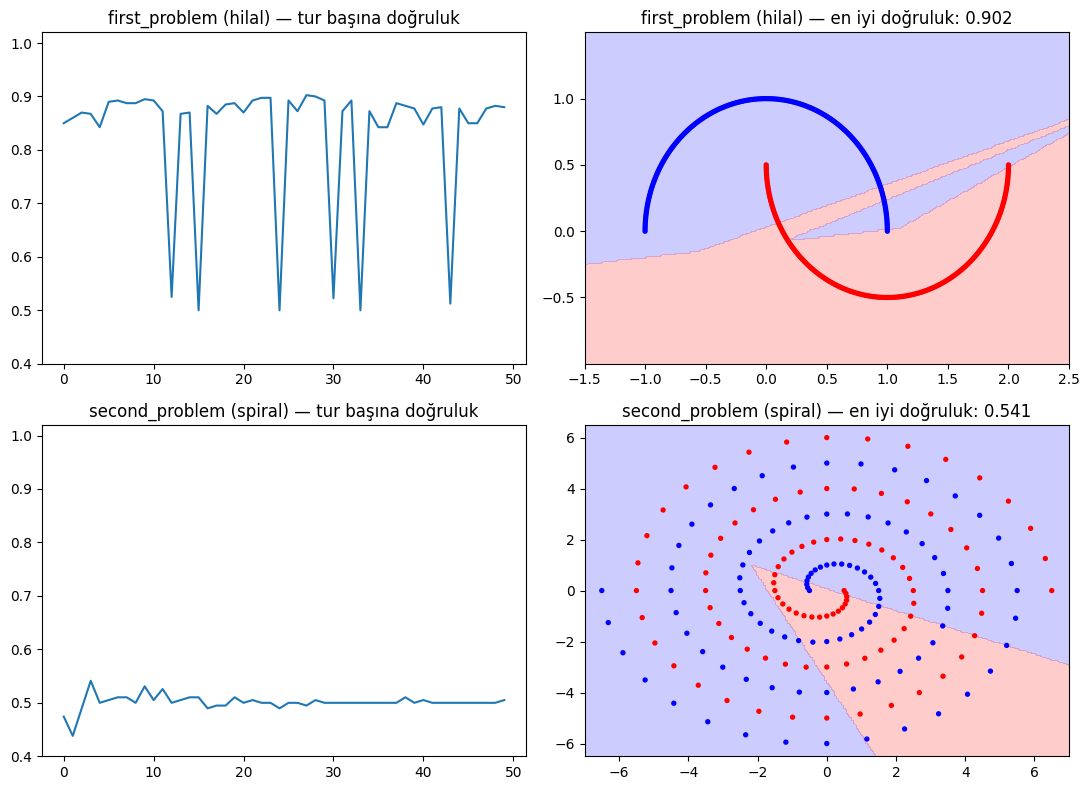

In [7]:
# Varsayılan mimari (2-4-1) ile ilk deneme, eta = 0.01
plt.figure(figsize=(11, 8))
k = 1   # sıradaki grafik kutusunun numarası

for name in datasets:
    X, y = datasets[name]
    best_acc, best_weights, final_weights, history = train(X, y, [2, 4, 1], 0.01)

    # Sol kutu: her turun sonundaki doğruluk
    plt.subplot(2, 2, k)
    plt.plot(history)
    plt.ylim(0.4, 1.02)
    plt.title(name + " — tur başına doğruluk")

    # Sağ kutu: en iyi ağırlıkların karar sınırı
    plt.subplot(2, 2, k + 1)
    plot_boundary(best_weights, X, y, name + " — en iyi doğruluk: " + str(round(best_acc, 3)))

    k = k + 2

plt.tight_layout()
plt.show()

**Yorum.**

- **Hilal:** Doğruluk %85–90 arasında gidip geliyor, arada bir %50'ye düşüp geri çıkıyor. Kural hiç durmuyor, çünkü hatasız bir çözüm bulamıyor ve her yanlış örnek ağırlıkları yeniden oynatıyor. Slayt 20'deki "yakınsama kanıtı" sadece doğrusal ayrılabilir veri için geçerli; burada o garanti yok. Bu yüzden son turdaki değil, **gördüğümüz en iyi** ağırlıkları saklıyoruz (burada %90.2).
- **Spiral:** İlk birkaç turdan sonra doğruluk %50'ye, yani şans seviyesine yapışıyor.
- **Karar sınırları:** Hilalde 4 gizli nöron olmasına rağmen sınır neredeyse tek bir düz çizgi. Gizli katman var ama hilalin kıvrımını yakalayamamış.

## 5. Madde 4 ve 5 — Öğrenme oranı ve mimari deneyi

Tek bir deneyle iki maddeyi de cevaplıyoruz: **5 mimari × 4 öğrenme oranı**, her birleşim **5 farklı rastgele başlangıçla**.

Neden 5 başlangıç? Sonuç başlangıç ağırlıklarına çok bağlı. Tek çalıştırmaya bakıp "şu oran daha iyi" demek şans eseri olabilir. Bu yüzden 5 çalıştırmanın ortalamasına ve en iyisine birlikte bakıyoruz.

Doğruluğu bütün veri üzerinde ölçüyoruz (eğitim/test ayrımı yok), çünkü soru ağın bu şekli öğrenip öğrenemediği.

In [8]:
ARCHS = {
    "2-1 (gizli katman yok)": [2, 1],        # tek perceptron: karşılaştırma tabanı
    "2-4-1 (varsayılan)":     [2, 4, 1],     # varsayılan mimari
    "2-16-1":                 [2, 16, 1],    # daha çok nöron
    "2-64-1":                 [2, 64, 1],    # çok daha çok nöron
    "2-8-8-1":                [2, 8, 8, 1],  # daha çok katman
}
ETAS = [0.001, 0.01, 0.1, 1.0]   # denenecek öğrenme oranları
SEEDS = [0, 1, 2, 3, 4]          # 5 farklı rastgele başlangıç

rows = []          # her eğitimin sonucu (tablo için)
best_models = {}   # her veri + mimari için bulunan en iyi model (çizim için)

# Bu hücre yaklaşık 1 dakika sürer: 2 veri x 5 mimari x 4 oran x 5 başlangıç = 200 eğitim.
for data_name in datasets:
    X, y = datasets[data_name]

    for arch_name in ARCHS:
        layers = ARCHS[arch_name]

        for eta in ETAS:
            for seed in SEEDS:
                best_acc, best_weights, final_weights, history = train(X, y, layers, eta, seed=seed)
                rows.append([data_name, arch_name, eta, seed, best_acc])

                # Bu veri + mimari için şimdiye kadarki en iyi modeli sakla
                key = data_name + " " + arch_name
                if key not in best_models or best_acc > best_models[key][0]:
                    best_models[key] = [best_acc, best_weights, eta]

results = pd.DataFrame(rows, columns=["veri", "mimari", "eta", "seed", "doğruluk"])
print("Toplam eğitim sayısı:", len(results))

Toplam eğitim sayısı: 200


In [9]:
# Sonuçları tabloya dök: satırlar = mimari, sütunlar = öğrenme oranı
for data_name in datasets:
    part = results[results["veri"] == data_name]   # sadece bu verinin satırları

    mean_table = part.pivot_table(index="mimari", columns="eta", values="doğruluk", aggfunc="mean")
    max_table = part.pivot_table(index="mimari", columns="eta", values="doğruluk", aggfunc="max")

    # reindex: satırları ARCHS'taki sıraya dizer
    print(data_name, "— 5 başlangıcın ORTALAMA doğruluğu")
    display(mean_table.reindex(list(ARCHS)).round(3))

    print(data_name, "— 5 başlangıcın EN İYİ doğruluğu")
    display(max_table.reindex(list(ARCHS)).round(3))

first_problem (hilal) — 5 başlangıcın ORTALAMA doğruluğu


eta,0.001,0.010,0.100,1.000
mimari,,,,
2-1 (gizli katman yok),0.883,0.884,0.888,0.886
2-4-1 (varsayılan),0.870,0.899,0.895,0.862
2-16-1,0.962,0.976,0.912,0.863
2-64-1,0.964,0.996,0.912,0.864
2-8-8-1,0.877,0.894,0.859,0.649


first_problem (hilal) — 5 başlangıcın EN İYİ doğruluğu


eta,0.001,0.010,0.100,1.000
mimari,,,,
2-1 (gizli katman yok),0.890,0.892,0.892,0.888
2-4-1 (varsayılan),0.938,0.918,0.920,0.870
2-16-1,0.988,1.000,0.925,0.872
2-64-1,0.995,1.000,0.945,0.875
2-8-8-1,0.952,0.955,0.880,0.882


second_problem (spiral) — 5 başlangıcın ORTALAMA doğruluğu


eta,0.001,0.010,0.100,1.000
mimari,,,,
2-1 (gizli katman yok),0.545,0.548,0.545,0.543
2-4-1 (varsayılan),0.539,0.531,0.505,0.505
2-16-1,0.544,0.544,0.512,0.505
2-64-1,0.562,0.556,0.512,0.505
2-8-8-1,0.526,0.529,0.506,0.515


second_problem (spiral) — 5 başlangıcın EN İYİ doğruluğu


eta,0.001,0.010,0.100,1.000
mimari,,,,
2-1 (gizli katman yok),0.557,0.567,0.557,0.562
2-4-1 (varsayılan),0.562,0.557,0.505,0.505
2-16-1,0.562,0.557,0.521,0.505
2-64-1,0.593,0.588,0.515,0.505
2-8-8-1,0.546,0.546,0.510,0.526


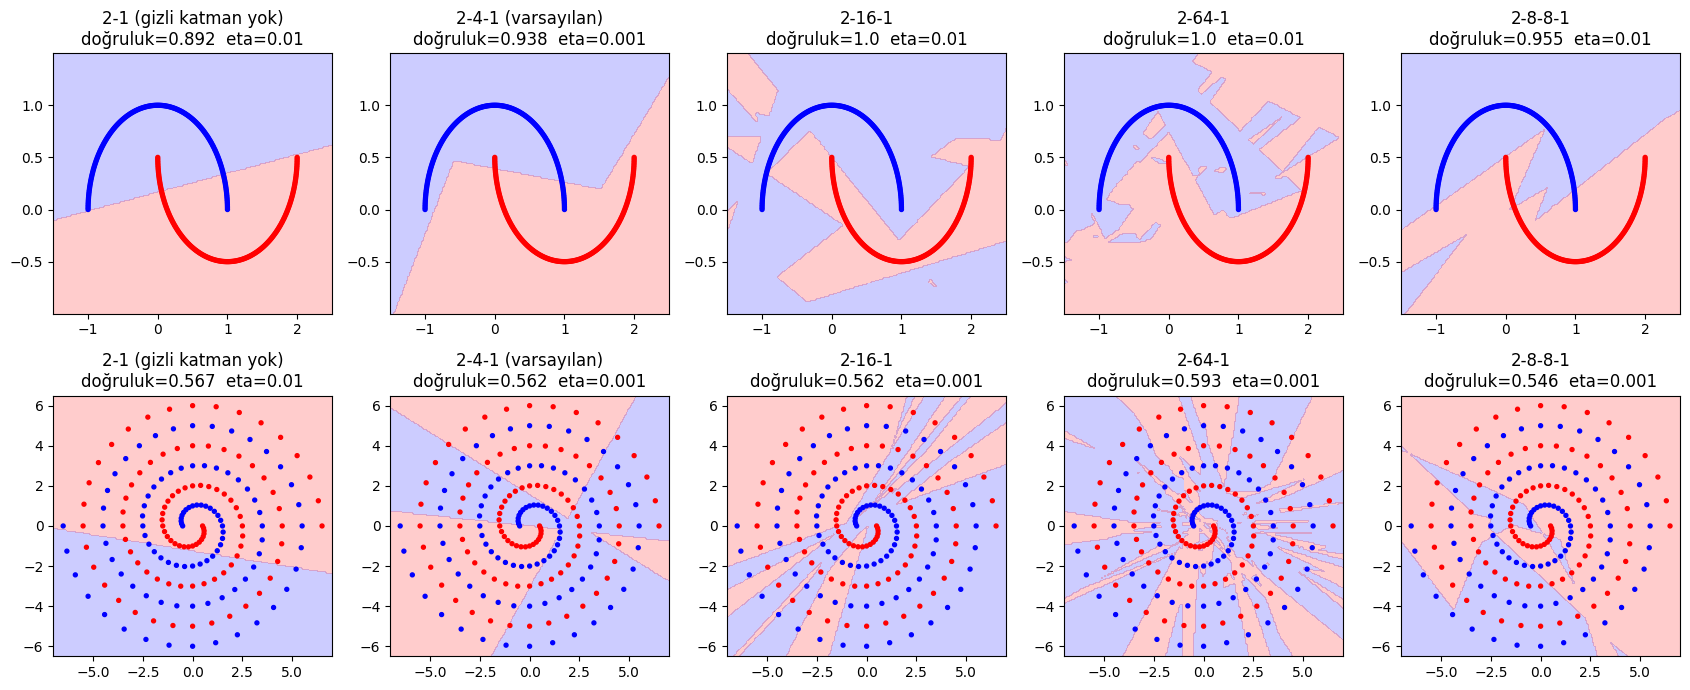

In [10]:
# Her mimarinin bulduğu en iyi modelin karar sınırı
plt.figure(figsize=(17, 7))
k = 1   # sıradaki grafik kutusunun numarası

for data_name in datasets:
    X, y = datasets[data_name]

    for arch_name in ARCHS:
        best_acc, best_weights, eta = best_models[data_name + " " + arch_name]

        plt.subplot(2, 5, k)
        plot_boundary(best_weights, X, y, arch_name + "\ndoğruluk=" + str(round(best_acc, 3)) + "  eta=" + str(eta))

        k = k + 1

plt.tight_layout()
plt.show()

### Madde 4 — Öğrenme oranını değiştirmek sonucu tutarlı şekilde iyileştiriyor mu?

**Hayır.** Ortalama tablolarını soldan sağa (η küçükten büyüğe) okuyalım:

- **Gizli katman yokken (2-1) η neredeyse hiçbir şeyi değiştirmiyor:** hilalde 0.883, 0.884, 0.888, 0.886. Sebebi şu: eşik fonksiyonu sadece toplamın *işaretine* bakar. η bütün düzeltmeleri aynı oranda büyütür ya da küçültür; ağırlık vektörünün boyu değişir ama yönü, yani çizdiği çizgi değişmez. Ağırlıkları sıfırdan başlatsaydık η'nın hiçbir etkisi olmazdı; buradaki küçük farklar rastgele başlangıçtan geliyor.
- **Gizli katman varken büyük η açıkça zarar veriyor:** hilalde `2-64-1` için 0.964 → 0.996 → 0.912 → 0.864, `2-8-8-1` için 0.877 → 0.894 → 0.859 → 0.649. η = 1.0'da gizli katmanlı bütün ağlar gizli katmansız tek perceptronun (0.886) altına düşüyor.
- **Ama "ne kadar küçük o kadar iyi" de değil:** hilalde 0.001'den 0.01'e çıkmak gizli katmanlı dört mimarinin dördünde de ortalamayı artırdı. η çok küçük olunca çıkış katmanı 50 turda rastgele başlangıcından yeterince uzaklaşamıyor.
- **Spiralde η'nın bir önemi yok:** bütün değerler 0.50–0.56 arasında. Büyük η'da tam şans seviyesine (0.505) iniyor.

Yani iyi bir aralık var (burada 0.001–0.01), onun dışına çıkınca sonuç kötüleşiyor. Büyük η'nın neden zarar verdiğini Bölüm 6'da ölçüyoruz: bu kuralda η, gizli nöronların ne kadar hızlı birbirinin kopyasına dönüşeceğini belirliyor.

### Madde 5 — Mimarilerin karşılaştırması

Hilal verisinde η = 0.01 sütunu (5 başlangıcın ortalaması / en iyisi):

| Mimari | Ortalama | En iyi | Varsayılana göre |
|---|---|---|---|
| 2-1 (gizli katman yok) | 0.884 | 0.892 | biraz kötü |
| **2-4-1 (varsayılan)** | 0.899 | 0.918 | — |
| 2-16-1 | 0.976 | 1.000 | belirgin şekilde iyi |
| 2-64-1 | 0.996 | 1.000 | en iyi |
| 2-8-8-1 | 0.894 | 0.955 | aynı seviyede |

- **Hilalde tek gizli katmanı genişletmek işe yarıyor:** 4 → 16 → 64 nöronla ortalama 0.899 → 0.976 → 0.996 oluyor ve %100'e ulaşan çalıştırmalar var.
- **Katman eklemek işe yaramıyor:** `2-8-8-1` toplam 16 gizli nörona sahip ama aynı sayıda nöronu tek katmanda tutan `2-16-1`'in (0.976) çok gerisinde, 0.894'te kalıyor. Bu, gizli katmanı hiç olmayan tek perceptronla (0.884) neredeyse aynı.
- **Spiralde hiçbir mimari işe yaramıyor:** bütün ortalamalar 0.53–0.56 arasında. En iyi tek sonuç `2-64-1` ile 0.593; yani 194 noktanın 115'i.
- **Karar sınırı grafiklerine dikkat:** `2-16-1` ve `2-64-1` hilali %100 ayırıyor ama sınır hilal şeklinde düzgün bir eğri değil, rastgele yönlere bakan düz çizgilerden oluşan köşeli bir şekil. Bunun neden böyle olduğu Bölüm 6'da açıklanıyor.

**Bu deneyde bulduğumuz en iyi sonuçlar:** hilal için **%100** (`2-16-1` ve `2-64-1`, η = 0.01), spiral için **%59.3** (`2-64-1`, η = 0.001).

## 6. Madde 6 — Katman ya da nöron eklemek neden her zaman işe yaramıyor?

Bölüm 3'te formülden iki sonuç çıkarmıştık. Şimdi ikisini de ölçüyoruz.

### 6.1 Gizli nöronlar birbirinin kopyasına dönüşüyor mu?

İki nöronun ağırlık vektörleri arasındaki **kosinüs benzerliği** yönlerinin ne kadar aynı olduğunu söyler: $+1$ = tamamen aynı yön, $0$ = alakasız. Aynı yöne bakan iki nöron aynı çizgiyi çizer, yani ikincisi boşa durur.

In [11]:
# Bir katmandaki bütün nöron çiftlerinin ortalama kosinüs benzerliği.
# Kosinüs benzerliği: iki vektörün yönü ne kadar aynı? +1 = aynı yön, 0 = alakasız.
def mean_cosine(W):
    total = 0
    count = 0
    for i in range(len(W)):               # her nöron çifti (i, j) için
        for j in range(i + 1, len(W)):
            cos = (W[i] @ W[j]) / (np.linalg.norm(W[i]) * np.linalg.norm(W[j]))
            total = total + cos
            count = count + 1
    return total / count


rows = []

for data_name in datasets:
    X, y = datasets[data_name]

    for eta in ETAS:
        W_before = init_weights([2, 16, 1], 0)[0]    # eğitimden önce gizli katmanın ağırlıkları

        best_acc, best_weights, final_weights, history = train(X, y, [2, 16, 1], eta, seed=0)
        W_after = final_weights[0]                   # eğitimden sonra gizli katmanın ağırlıkları

        # Sonuç 1'in kontrolü: iki nöron arasındaki fark eğitim boyunca hiç değişmemeli,
        # çünkü ikisine de hep aynı vektör eklendi.
        diff_before = W_before[0] - W_before[1]
        diff_after = W_after[0] - W_after[1]
        diff_same = np.allclose(diff_before, diff_after)

        rows.append([data_name, eta, round(mean_cosine(W_before), 2), round(mean_cosine(W_after), 2), diff_same])

display(pd.DataFrame(rows, columns=["veri", "eta", "benzerlik (önce)", "benzerlik (sonra)", "nöron farkı sabit mi"]))

,veri,eta,benzerlik (önce),benzerlik (sonra),nöron farkı sabit mi
0,first_problem (hilal),0.001,-0.03,0.46,True
1,first_problem (hilal),0.010,-0.03,0.96,True
2,first_problem (hilal),0.100,-0.03,1.00,True
3,first_problem (hilal),1.000,-0.03,1.00,True
4,second_problem (spiral),0.001,-0.03,0.72,True
5,second_problem (spiral),0.010,-0.03,0.99,True
6,second_problem (spiral),0.100,-0.03,1.00,True
7,second_problem (spiral),1.000,-0.03,1.00,True


**Yorum.**

- **"Nöron farkı sabit mi" sütunu her satırda `True`.** İki gizli nöron arasındaki fark eğitim boyunca hiç değişmemiş. Bölüm 3'teki Sonuç 1 birebir doğrulandı: kural bütün nöronlara aynı vektörü ekliyor.
- **Benzerlik eğitimden önce yaklaşık 0** (nöronlar rastgele, farklı yönlere bakıyor). Eğitimden sonra η büyüdükçe 1'e gidiyor: hilalde 0.46 → 0.96 → 1.00 → 1.00.
- **Benzerlik 1.00 olduğunda 16 nöronun hepsi aynı çizgiyi çiziyor.** Kâğıt üzerinde 16 nöron var, pratikte 1 tane. Bölüm 5'te η = 0.1 ve 1.0 sütunlarında gizli katmanlı ağların tek perceptron seviyesine (hilalde yaklaşık 0.86) düşmesinin sebebi bu.

η'nın rolü de buradan anlaşılıyor: ortak eklenen vektör η ile orantılı büyür. η küçükken rastgele başlangıç baskın kalır ve nöronlar farklı kalır; η büyükken ortak kısım baskın çıkar ve nöronlar kopyalaşır.

### 6.2 Kontrol deneyi: gizli katmanı hiç eğitmesek ne olur?

Gizli katman bu kuralla gerçekten bir şey öğreniyorsa, onu eğitmek eğitmemekten daha iyi sonuç vermeli. Aynı ağları bu sefer gizli katmanı **rastgele başlangıç değerlerinde dondurarak** eğitiyoruz: sadece çıkış nöronu öğreniyor (`update_hidden=False`).

In [12]:
rows = []

for data_name in datasets:
    X, y = datasets[data_name]

    for arch_name in ["2-16-1", "2-64-1", "2-8-8-1"]:
        layers = ARCHS[arch_name]

        # Gizli katmanlar donuk, sadece çıkış katmanı öğreniyor (eta = 0.01, 5 başlangıcın ortalaması)
        total = 0
        for seed in SEEDS:
            best_acc, best_weights, final_weights, history = train(X, y, layers, 0.01, seed=seed, update_hidden=False)
            total = total + best_acc
        frozen_mean = total / len(SEEDS)

        row = [data_name, arch_name, frozen_mean]

        # Karşılaştırma: aynı mimarinin Bölüm 5'teki sonuçları (bütün katmanlar kuralla güncellenmişti)
        part = results[(results["veri"] == data_name) & (results["mimari"] == arch_name)]
        means = part.groupby("eta")["doğruluk"].mean()
        for eta in ETAS:
            row.append(means[eta])

        rows.append(row)

table = pd.DataFrame(rows, columns=["veri", "mimari", "gizli katman DONUK",
                                    "kuralla, eta=0.001", "kuralla, eta=0.01", "kuralla, eta=0.1", "kuralla, eta=1.0"])
display(table.round(3))

,veri,mimari,gizli katman DONUK,"kuralla, eta=0.001","kuralla, eta=0.01","kuralla, eta=0.1","kuralla, eta=1.0"
0,first_problem (hilal),2-16-1,0.972,0.962,0.976,0.912,0.863
1,first_problem (hilal),2-64-1,1.000,0.964,0.996,0.912,0.864
2,first_problem (hilal),2-8-8-1,0.772,0.877,0.894,0.859,0.649
3,second_problem (spiral),2-16-1,0.592,0.544,0.544,0.512,0.505
4,second_problem (spiral),2-64-1,0.627,0.562,0.556,0.512,0.505
5,second_problem (spiral),2-8-8-1,0.559,0.526,0.529,0.506,0.515


**Yorum.**

- **Tek gizli katmanlı ağlarda gizli katmanı hiç eğitmemek, kuralla eğitmek kadar iyi ya da daha iyi.** Hilalde `2-16-1`: donuk 0.972, kuralla en iyi 0.976 (fark yok denecek kadar az). `2-64-1`: donuk 1.000, kuralla en iyi 0.996. Spiralde donuk hali her seferinde daha iyi: 0.592'ye karşı 0.544 ve 0.627'ye karşı 0.562.
- **Demek ki kural gizli katmana işe yarar bir şey öğretmiyor.** Hilaldeki iyi sonuçlar iki şeyden geliyor: gizli katmanın *rastgele* başlangıç çizgileri ve çıkış nöronunun bu çizgileri Rosenblatt kuralıyla doğru şekilde birleştirmesi. Yeterince çok rastgele çizgi olunca (16, 64) aralarından hilali ayıracak bir birleşim çıkıyor. Bölüm 5'teki köşeli karar sınırlarının sebebi de bu.
- **Tek istisna hilalde `2-8-8-1`:** donuk 0.772, kuralla 0.877–0.894. Burada kural yardım etmiş görünüyor, ama ulaştığı yer gizli katmansız tek perceptronun seviyesi (0.884). Bizim yorumumuz: üst üste iki rastgele katman kötü bir başlangıç veriyor; kural nöronları ortak bir yöne çekerek ağı tek çizgiye yaklaştırıyor ve bu, o kötü başlangıçtan daha iyi. Yani ağ iki gizli katmanını kullanmayı öğrenmiyor, onları etkisizleştiriyor.

### Madde 6'nın cevabı

Ağa nöron ya da katman eklemek **kapasiteyi**, yani ağın *çizebileceği* şekillerin zenginliğini artırır. Ama bu kapasitenin kullanılabilmesi için gizli nöronların birbirinden farklı ve işe yarar çizgiler **öğrenmesi** gerekir. Kullandığımız kural bunu yapamıyor, çünkü:

1. **Bütün gizli nöronlara aynı güncellemeyi veriyor** (Bölüm 3 Sonuç 1, Bölüm 6.1'de ölçüldü). Eklenen her nöron ya rastgele başlangıcında kalıyor (küçük η) ya da diğerlerinin kopyası oluyor (büyük η).
2. **Gizli nöronun çıkışa hangi işaretle bağlı olduğuna bakmıyor** (Bölüm 3 Sonuç 2). Bu yüzden güncelleme bazı nöronları yanlış yöne itiyor.
3. **Gizli nöronun kendi hedefi yok.** Hata sadece çıkışta ölçülüyor; bu hatada hangi gizli nöronun ne kadar payı olduğunu söyleyen bir mekanizma yok. Buna *credit assignment* (pay dağıtma) problemi denir ve backpropagation tam olarak bunu çözer.

Sonuçlar da bununla uyumlu:

- **Genişlik hilalde işe yaradı**, ama öğrenme sayesinde değil; daha çok rastgele çizgi arasından işe yarar bir birleşim çıkma şansı arttığı için (Bölüm 6.2).
- **Derinlik işe yaramadı.** İkinci gizli katman, birincinin rastgele çıkışlarının yine rastgele birleşimini alıyor ve aynı hatalı kuralla güncelleniyor.
- **Spiralde hiçbir şey işe yaramadı.** Spirali ayırmak için çok sayıda çizginin doğru yerlere yerleşmesi gerekiyor; rastgele çizgiler bunun için yetmiyor, kural da onları doğru yere taşıyamıyor.

## 7. Özet

| Madde | Kısa cevap |
|---|---|
| 1 | Hebb: $\Delta w = \eta x y$, hata terimi yok, ağırlıklar sınırsız büyür. Rosenblatt: $\Delta w = \eta (y - \hat{y}) x$, sadece yanlış tahminde günceller. |
| 2 | Kural çıkış katmanında tam olarak Rosenblatt. Gizli katmanlarda Rosenblatt biçiminde ama nöronun kendi hatası yerine çıkışın hatasını kullanıyor; Hebb değil. |
| 3 | Sadece NumPy ile uygulandı: `forward` ve `train`. Türev ya da hazır kütüphane yok. |
| 4 | η'yı değiştirmek tutarlı iyileşme sağlamıyor. Tek perceptronda etkisi yok denecek kadar az; gizli katmanlı ağlarda büyük η zarar veriyor. |
| 5 | Hilalde tek gizli katmanı genişletmek doğruluğu 0.899'dan 0.996'ya çıkardı; katman eklemek çıkarmadı. Spiralde hiçbir mimari %60'ı geçemedi. |
| 6 | Kapasite artıyor ama kural gizli nöronlara farklı ve işe yarar şeyler öğretemiyor; hepsine aynı güncellemeyi veriyor. |

| Veri | En iyi doğruluk | Mimari | η |
|---|---|---|---|
| first_problem (hilal) | 1.000 | 2-16-1, 2-64-1 | 0.01 |
| second_problem (spiral) | 0.593 | 2-64-1 | 0.001 |